# Vẽ đánh đổi thiên lệch – phương sai (mục 2.2.4): Bias², Variance và tổng sai số theo bậc đa thức,

ước lượng bằng mô phỏng 200 tập huấn luyện 15 điểm; cùng sai số huấn luyện và kiểm tra trên một tập dữ liệu

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

OUTPUT = Path('bias_variance.png')   # ảnh lưu cạnh notebook
NOISE_VARIANCE = 0.2 ** 2                                         # σ², nhiễu không thể tránh

def make_data(n, rng):
    """Sinh n điểm (x, y) với y = sin(2πx) + nhiễu, x trong [0, 1)."""
    x = np.sort(rng.uniform(0, 1, n))
    y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, n)
    return x.reshape(-1, 1), y

def poly_model(degree):
    """Hồi quy đa thức bậc degree (chuẩn hóa trước khi lũy thừa để nghiệm ổn định)."""
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                         StandardScaler(), LinearRegression())

degrees = list(range(1, 8))
x_grid = np.linspace(0.05, 0.95, 50).reshape(-1, 1)
f_true = np.sin(2 * np.pi * x_grid.ravel())                       # hàm thật f(x)
bias2_values, variance_values = [], []
for degree in degrees:
    sim_rng = np.random.default_rng(7)                            # mọi bậc dùng cùng 200 tập huấn luyện
    predictions = np.array([poly_model(degree).fit(*make_data(15, sim_rng)).predict(x_grid)
                            for _ in range(200)])
    bias2_values.append(np.mean((predictions.mean(axis=0) - f_true) ** 2))
    variance_values.append(np.mean(predictions.var(axis=0)))
total_values = np.array(bias2_values) + np.array(variance_values) + NOISE_VARIANCE

Sai số huấn luyện và kiểm tra trên một tập dữ liệu cụ thể (giống notebook 07)

In [2]:
rng = np.random.default_rng(1)
X_train, y_train = make_data(15, rng)
make_data(15, rng)                                                # bỏ qua tập xác thực
X_test, y_test = make_data(500, rng)
curve_degrees = list(range(1, 13))                              # hình (b): bậc 1 đến 12
train_mse, test_mse = [], []
for degree in curve_degrees:
    model = poly_model(degree).fit(X_train, y_train)
    train_mse.append(np.mean((model.predict(X_train) - y_train) ** 2))
    test_mse.append(np.mean((model.predict(X_test) - y_test) ** 2))

Vẽ hình và lưu ảnh.

bậc 1: Bias² = 0.1539, Variance = 0.0401, tổng = 0.2340
bậc 2: Bias² = 0.1444, Variance = 0.1138, tổng = 0.2982
bậc 3: Bias² = 0.0026, Variance = 0.0161, tổng = 0.0586
bậc 4: Bias² = 0.0043, Variance = 0.0884, tổng = 0.1326
bậc 5: Bias² = 0.0015, Variance = 0.2132, tổng = 0.2547
bậc 6: Bias² = 0.0280, Variance = 4.6476, tổng = 4.7156
bậc 7: Bias² = 0.1311, Variance = 27.9201, tổng = 28.0912
Đã lưu hình: bias_variance.png


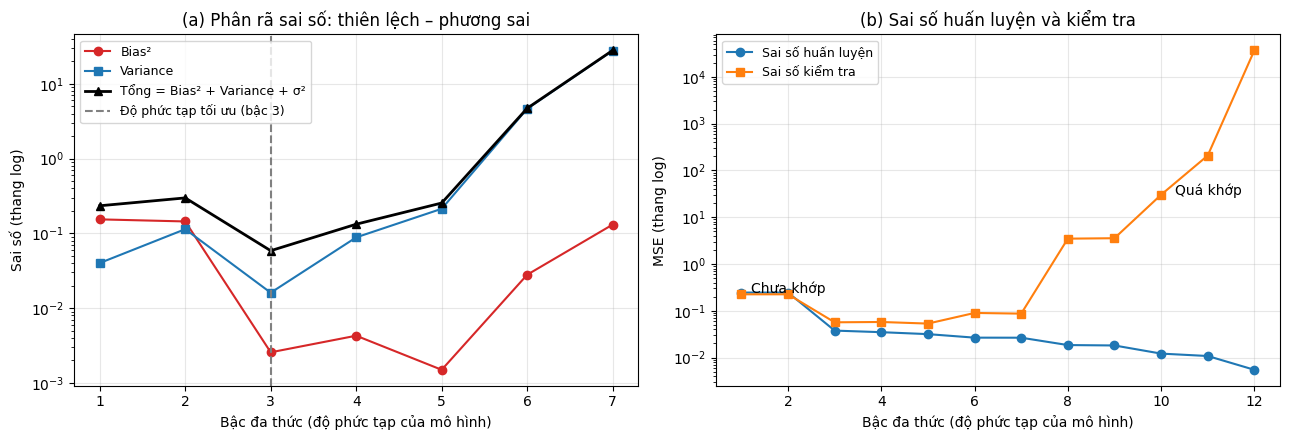

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(degrees, bias2_values, 'o-', color='tab:red', label='Bias²')
axes[0].plot(degrees, variance_values, 's-', color='tab:blue', label='Variance')
axes[0].plot(degrees, total_values, 'k^-', lw=2, label='Tổng = Bias² + Variance + σ²')
best = degrees[int(np.argmin(total_values))]
axes[0].axvline(best, color='gray', ls='--', label=f'Độ phức tạp tối ưu (bậc {best})')
axes[0].set_yscale('log')
axes[0].set_xlabel('Bậc đa thức (độ phức tạp của mô hình)')
axes[0].set_ylabel('Sai số (thang log)')
axes[0].set_title('(a) Phân rã sai số: thiên lệch – phương sai')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

axes[1].plot(curve_degrees, train_mse, 'o-', label='Sai số huấn luyện')
axes[1].plot(curve_degrees, test_mse, 's-', label='Sai số kiểm tra')
axes[1].set_yscale('log')
axes[1].set_xlabel('Bậc đa thức (độ phức tạp của mô hình)')
axes[1].set_ylabel('MSE (thang log)')
axes[1].set_title('(b) Sai số huấn luyện và kiểm tra')
axes[1].annotate('Chưa khớp', xy=(1.2, train_mse[0]), fontsize=10)
axes[1].annotate('Quá khớp', xy=(10.3, test_mse[9]), fontsize=10)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT, dpi=150)
for degree, b, v, t in zip(degrees, bias2_values, variance_values, total_values):
    print(f'bậc {degree}: Bias² = {b:.4f}, Variance = {v:.4f}, tổng = {t:.4f}')
print('Đã lưu hình:', OUTPUT)